# Task 2 (Part 2): Proposed GNN Model, Graph Construction & First Results


## 0. Setup & Environment

In [ ]:
!pip install -q networkx

import os, re, time, shutil, subprocess, urllib.request, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import networkx as nx

from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import RobustScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, auc
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
np.random.seed(42)
print('Using device:', DEVICE)

ZIP_DIR = '/content/Ninapro_Zips'
LOCAL_DIR = '/content/Ninapro_DB3'
os.makedirs(ZIP_DIR, exist_ok=True)
os.makedirs(LOCAL_DIR, exist_ok=True)

Using device: cuda


## 1. Load Ninapro DB3 & Extract 12-Node Electrode Features

In [ ]:
BASE_URL = 'https://ninapro.hevs.ch/files/db3_Preproc'
for s in range(1, 12):
    zf = f's{s}_0.zip'
    zip_path = os.path.join(ZIP_DIR, zf)
    if not os.path.exists(zip_path) or os.path.getsize(zip_path) < 1000:
        url = f'{BASE_URL}/{zf}'
        r_dl = subprocess.run(['wget', '-q', '-c', url, '-O', zip_path])
        if r_dl.returncode != 0:
            urllib.request.urlretrieve(url, zip_path)
    subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR], capture_output=True, text=True)

for root, dirs, files in os.walk(LOCAL_DIR):
    for f in files:
        src = os.path.join(root, f)
        if f.startswith('._'): os.remove(src)
        elif f.endswith('.mat') and root != LOCAL_DIR:
            shutil.move(src, os.path.join(LOCAL_DIR, f))
shutil.rmtree(os.path.join(LOCAL_DIR, '__MACOSX'), ignore_errors=True)

WIN, STEP = 300, 150
FEATURE_TYPES = ['MAV', 'RMS', 'VAR', 'WL', 'ZC', 'SSC']
THR_FACTOR = 0.1

def window_features(emg, lbl):
    emg = emg.astype(np.float64) * 1000.0
    thr = THR_FACTOR * emg.std(axis=0)[None, :, None]
    W = sliding_window_view(emg, WIN, axis=0)[::STEP]
    L = sliding_window_view(lbl, WIN)[::STEP]
    ok = (L == L[:, :1]).all(axis=1)
    W, y = W[ok], L[ok, 0]
    d = np.diff(W, axis=-1)
    mav = np.abs(W).mean(-1)
    rms = np.sqrt((W ** 2).mean(-1))
    var = W.var(-1)
    wl  = np.abs(d).sum(-1)
    zc  = ((W[..., :-1] * W[..., 1:] < 0) & (np.abs(d) >= thr)).sum(-1)
    ssc = ((d[..., :-1] * d[..., 1:] < 0) & (np.abs(d[..., :-1] - d[..., 1:]) >= thr)).sum(-1)
    return np.hstack([mav, rms, var, wl, zc, ssc]), y

mat_files = sorted(os.path.join(LOCAL_DIR, f) for f in os.listdir(LOCAL_DIR) if f.endswith('.mat'))
X_parts, y_parts, s_parts = [], [], []
n_channels = 12

for fp in mat_files:
    base = os.path.basename(fp)
    m = re.match(r'S(\d+)_E(\d+)', base)
    sid = int(m.group(1))
    mat = sio.loadmat(fp)
    emg, lbl = mat['emg'], mat['restimulus'].ravel().astype(np.int64)
    Xf, yf = window_features(emg, lbl)
    X_parts.append(Xf); y_parts.append(yf); s_parts.append(np.full(len(yf), sid))

feat_cols = [f'{f}_Ch{c}' for f in FEATURE_TYPES for c in range(1, n_channels + 1)]
df = pd.DataFrame(np.vstack(X_parts), columns=feat_cols)
df['Gesture_Label'] = np.concatenate(y_parts)
df['Subject_ID']    = np.concatenate(s_parts)

unique_classes = sorted(df['Gesture_Label'].unique())
label_map = {c: i for i, c in enumerate(unique_classes)}
df['y'] = df['Gesture_Label'].map(label_map)
NUM_CLASSES = len(unique_classes)

TRAIN_SUBJ, VAL_SUBJ, TEST_SUBJ = [1, 2, 3, 4, 5, 6, 7, 8], [9], [10, 11]
df_train_raw = df[df['Subject_ID'].isin(TRAIN_SUBJ)].copy()
df_val       = df[df['Subject_ID'].isin(VAL_SUBJ)].copy()
df_test      = df[df['Subject_ID'].isin(TEST_SUBJ)].copy()

active_med = int(df_train_raw[df_train_raw['y'] > 0]['y'].value_counts().median())
df_rest_tr = df_train_raw[df_train_raw['y'] == 0].sample(n=min(len(df_train_raw[df_train_raw['y']==0]), active_med * 2), random_state=42)
df_train   = pd.concat([df_rest_tr, df_train_raw[df_train_raw['y'] > 0]], ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)

skew_cols = [c for c in feat_cols if c.startswith(('MAV', 'RMS', 'VAR', 'WL'))]
def transform_skew(frame):
    X = frame[feat_cols].copy()
    for c in skew_cols:
        X[c] = np.log1p(np.maximum(0.0, X[c]))
    return X.values

scaler = RobustScaler()
X_train_flat = scaler.fit_transform(transform_skew(df_train))
X_val_flat   = scaler.transform(transform_skew(df_val))
X_test_flat  = scaler.transform(transform_skew(df_test))

y_train = df_train['y'].values
y_val   = df_val['y'].values
y_test  = df_test['y'].values

X_train_nodes = np.transpose(X_train_flat.reshape(-1, 6, 12), (0, 2, 1))
X_val_nodes   = np.transpose(X_val_flat.reshape(-1, 6, 12),   (0, 2, 1))
X_test_nodes  = np.transpose(X_test_flat.reshape(-1, 6, 12),  (0, 2, 1))

print(f'Node tensor shapes -> Train: {X_train_nodes.shape} | Val: {X_val_nodes.shape} | Test: {X_test_nodes.shape}')

Node tensor shapes -> Train: (168816, 12, 6) | Val: (32962, 12, 6) | Test: (61745, 12, 6)


## 2. Graph Construction (After Splitting)

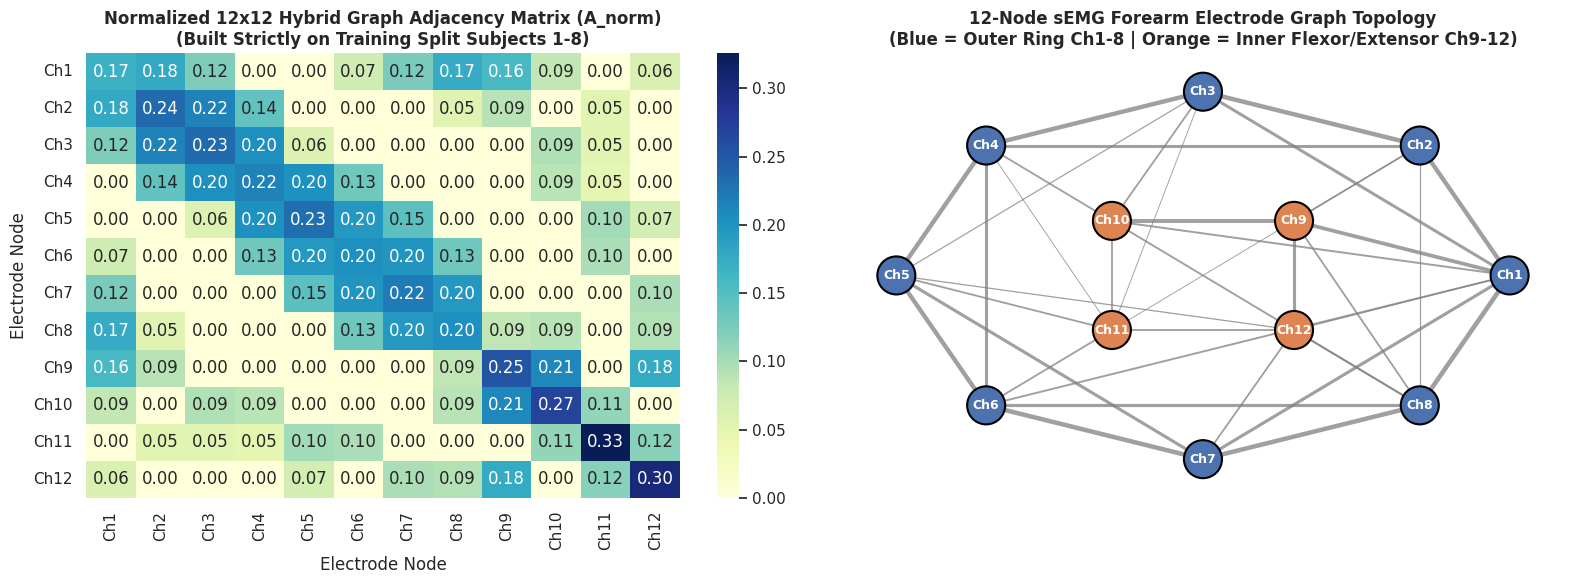

In [ ]:
A_spatial = np.zeros((12, 12), dtype=np.float32)

for i in range(8):
    n1 = (i + 1) % 8
    n2 = (i + 2) % 8
    A_spatial[i, n1] = A_spatial[n1, i] = 1.0
    A_spatial[i, n2] = A_spatial[n2, i] = 0.5

chain_pairs = [(8, 9), (9, 10), (10, 11), (8, 11), (0, 8), (1, 8), (2, 9), (3, 9), (4, 10), (5, 10), (6, 11), (7, 11)]
for u, v in chain_pairs:
    A_spatial[u, v] = A_spatial[v, u] = 0.75

rms_train = X_train_nodes[:, :, 1]
corr_train = pd.DataFrame(rms_train).rank().corr().values
np.fill_diagonal(corr_train, 0.0)

A_func = np.zeros((12, 12), dtype=np.float32)
k_neighbors = 3
for i in range(12):
    top_k_idx = np.argsort(corr_train[i])[::-1][:k_neighbors]
    for j in top_k_idx:
        if corr_train[i, j] > 0:
            A_func[i, j] = corr_train[i, j]
A_func = np.maximum(A_func, A_func.T)

alpha = 0.5
A_raw = alpha * A_spatial + (1.0 - alpha) * A_func
A_tilde = A_raw + np.eye(12, dtype=np.float32)

deg = np.sum(A_tilde, axis=1)
deg_inv_sqrt = np.power(deg, -0.5)
D_inv_sqrt = np.diag(deg_inv_sqrt)
A_norm = D_inv_sqrt @ A_tilde @ D_inv_sqrt
A_norm_tensor = torch.FloatTensor(A_norm).to(DEVICE)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(A_norm, annot=True, fmt='.2f', cmap='YlGnBu',
            xticklabels=[f'Ch{i}' for i in range(1, 13)],
            yticklabels=[f'Ch{i}' for i in range(1, 13)], ax=axes[0])
axes[0].set_title('Normalized 12x12 Hybrid Graph Adjacency Matrix (A_norm)\n(Built Strictly on Training Split Subjects 1-8)', fontweight='bold')
axes[0].set_xlabel('Electrode Node'); axes[0].set_ylabel('Electrode Node')

G = nx.Graph()
for i in range(12):
    G.add_node(i + 1, group='Ring (Ch1-8)' if i < 8 else 'Flex/Ext (Ch9-12)')
for i in range(12):
    for j in range(i + 1, 12):
        if A_raw[i, j] > 0.15:
            G.add_edge(i + 1, j + 1, weight=float(A_raw[i, j]))

pos = {}
for i in range(8):
    angle = 2 * np.pi * i / 8.0
    pos[i + 1] = (np.cos(angle), np.sin(angle))
for idx, ch in enumerate([9, 10, 11, 12]):
    angle = 2 * np.pi * idx / 4.0 + np.pi / 4.0
    pos[ch] = (0.42 * np.cos(angle), 0.42 * np.sin(angle))

node_colors = ['#4C72B0' if i < 8 else '#DD8452' for i in range(12)]
edges = G.edges(data=True)
edge_weights = [d['weight'] * 3.5 for (_, _, d) in edges]

nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=node_colors, node_size=750, edgecolors='black', linewidths=1.5)
nx.draw_networkx_labels(G, pos, ax=axes[1], labels={i: f'Ch{i}' for i in range(1, 13)}, font_color='white', font_weight='bold', font_size=9)
nx.draw_networkx_edges(G, pos, ax=axes[1], width=edge_weights, edge_color='gray', alpha=0.75)
axes[1].set_title('12-Node sEMG Forearm Electrode Graph Topology\n(Blue = Outer Ring Ch1-8 | Orange = Inner Flexor/Extensor Ch9-12)', fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Proposed GNN Architecture Diagram & Plain-Language Walkthrough

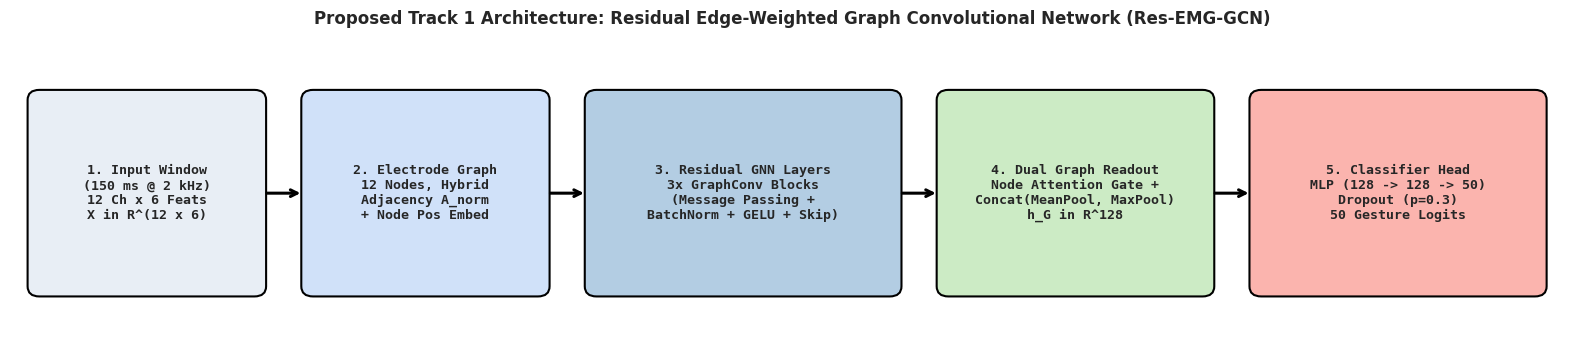

In [ ]:
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.set_xlim(0, 16)
ax.set_ylim(0, 3.8)
ax.axis('off')

blocks = [
    (0.3, 0.8, 2.2, 2.2, '#E8EEF5', '1. Input Window\n(150 ms @ 2 kHz)\n12 Ch x 6 Feats\nX in R^(12 x 6)'),
    (3.1, 0.8, 2.3, 2.2, '#D0E1F9', '2. Electrode Graph\n12 Nodes, Hybrid\nAdjacency A_norm\n+ Node Pos Embed'),
    (6.0, 0.8, 3.0, 2.2, '#B3CDE3', '3. Residual GNN Layers\n3x GraphConv Blocks\n(Message Passing +\nBatchNorm + GELU + Skip)'),
    (9.6, 0.8, 2.6, 2.2, '#CCEBC5', '4. Dual Graph Readout\nNode Attention Gate +\nConcat(MeanPool, MaxPool)\nh_G in R^128'),
    (12.8, 0.8, 2.8, 2.2, '#FBB4AE', '5. Classifier Head\nMLP (128 -> 128 -> 50)\nDropout (p=0.3)\n50 Gesture Logits')
]

for x, y, w, h, color, text in blocks:
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12', facecolor=color, edgecolor='black', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9.5, fontweight='bold', family='monospace')

arrows = [(2.6, 1.9, 3.0, 1.9), (5.5, 1.9, 5.9, 1.9), (9.1, 1.9, 9.5, 1.9), (12.3, 1.9, 12.7, 1.9)]
for x1, y1, x2, y2 in arrows:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle='->', lw=2.2, color='black'))

ax.set_title('Proposed Track 1 Architecture: Residual Edge-Weighted Graph Convolutional Network (Res-EMG-GCN)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Proposed GNN Implementation & Training (`Res-EMG-GCN`)

In [ ]:
class GraphConvBlock(nn.Module):
    def __init__(self, dim, dropout=0.2):
        super().__init__()
        self.W_neigh = nn.Linear(dim, dim, bias=False)
        self.W_self  = nn.Linear(dim, dim, bias=True)
        self.bn      = nn.BatchNorm1d(dim)
        self.drop    = nn.Dropout(dropout)

    def forward(self, H, A_norm):
        agg = torch.matmul(A_norm, H)
        out = self.W_neigh(agg) + self.W_self(H)
        out = self.bn(out.transpose(1, 2)).transpose(1, 2)
        out = F.gelu(out)
        out = self.drop(out)
        return H + out

class ProposedResEMGGCN(nn.Module):
    def __init__(self, num_nodes=12, in_features=6, hidden_dim=96, num_layers=3, num_classes=50, dropout=0.25):
        super().__init__()
        self.num_nodes = num_nodes
        self.pos_embed = nn.Parameter(torch.randn(1, num_nodes, hidden_dim) * 0.02)

        self.input_stem = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )

        self.gnn_layers = nn.ModuleList([
            GraphConvBlock(hidden_dim, dropout=dropout) for _ in range(num_layers)
        ])

        self.node_att = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1)
        )

        readout_dim = hidden_dim * 3
        self.classifier = nn.Sequential(
            nn.Linear(readout_dim, 192),
            nn.BatchNorm1d(192),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(192, num_classes)
        )

    def forward(self, X_node, A_norm):
        H = self.input_stem(X_node) + self.pos_embed
        for layer in self.gnn_layers:
            H = layer(H, A_norm)

        mean_pool = H.mean(dim=1)
        max_pool  = H.max(dim=1).values
        att_w     = torch.softmax(self.node_att(H), dim=1)
        att_pool  = (H * att_w).sum(dim=1)

        graph_emb = torch.cat([mean_pool, max_pool, att_pool], dim=-1)
        return self.classifier(graph_emb)

class_counts_tr = np.bincount(y_train, minlength=NUM_CLASSES)
cw = 1.0 / np.maximum(class_counts_tr, 1)
cw = cw / cw.sum() * NUM_CLASSES
weights_tensor = torch.FloatTensor(cw).to(DEVICE)

train_ds = TensorDataset(torch.FloatTensor(X_train_nodes), torch.LongTensor(y_train))
val_ds   = TensorDataset(torch.FloatTensor(X_val_nodes),   torch.LongTensor(y_val))
test_ds  = TensorDataset(torch.FloatTensor(X_test_nodes),  torch.LongTensor(y_test))

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=1024, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=1024, shuffle=False)

gnn_model = ProposedResEMGGCN(
    num_nodes=12, in_features=6, hidden_dim=96, num_layers=3, num_classes=NUM_CLASSES, dropout=0.25
).to(DEVICE)

print(gnn_model)
total_params = sum(p.numel() for p in gnn_model.parameters() if p.requires_grad)
print(f'Total Trainable Parameters: {total_params:,}')

ProposedResEMGGCN(
  (input_stem): Sequential(
    (0): Linear(in_features=6, out_features=96, bias=True)
    (1): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): GELU(approximate='none')
  )
  (gnn_layers): ModuleList(
    (0-2): 3 x GraphConvBlock(
      (W_neigh): Linear(in_features=96, out_features=96, bias=False)
      (W_self): Linear(in_features=96, out_features=96, bias=True)
      (bn): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (drop): Dropout(p=0.25, inplace=False)
    )
  )
  (node_att): Sequential(
    (0): Linear(in_features=96, out_features=48, bias=True)
    (1): Tanh()
    (2): Linear(in_features=48, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=288, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)


## 5. Train the Proposed GNN & Evaluate First Results on Unseen Amputee Subjects

In [ ]:
EPOCHS = 35
optimizer = torch.optim.AdamW(gnn_model.parameters(), lr=1.5e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)
criterion = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.05)

history = {'train_loss': [], 'val_loss': [], 'val_macro_f1': []}
best_val_f1 = -1.0
best_state = None

t0 = time.time()
for ep in range(1, EPOCHS + 1):
    gnn_model.train()
    tr_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = gnn_model(xb, A_norm_tensor)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * len(yb)
    scheduler.step()
    tr_loss /= len(train_ds)

    gnn_model.eval()
    val_loss = 0.0
    v_preds, v_trues = [], []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = gnn_model(xb, A_norm_tensor)
            loss = criterion(logits, yb)
            val_loss += loss.item() * len(yb)
            v_preds.append(logits.argmax(dim=-1).cpu().numpy())
            v_trues.append(yb.cpu().numpy())
    val_loss /= len(val_ds)
    val_f1 = f1_score(np.concatenate(v_trues), np.concatenate(v_preds), average='macro', zero_division=0)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['val_macro_f1'].append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {k: v.cpu().clone() for k, v in gnn_model.state_dict().items()}

    if ep % 5 == 0 or ep == 1:
        print(f'Epoch {ep:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro-F1: {val_f1:.4f}')

gnn_train_time = time.time() - t0
gnn_model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
os.makedirs('/content/models', exist_ok=True)
torch.save(gnn_model.state_dict(), '/content/models/Group02_NinaproDB3_task2_res_emg_gcn.pt')

gnn_model.eval()
t_probs, t_preds = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        logits = gnn_model(xb, A_norm_tensor)
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        t_probs.append(probs)
        t_preds.append(probs.argmax(axis=1))

y_prob_gnn = np.vstack(t_probs)
y_pred_gnn = np.concatenate(t_preds)
y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))

gnn_metrics = {
    'Model': 'Proposed Res-EMG-GCN (Track 1)',
    'Macro-F1': round(f1_score(y_test, y_pred_gnn, average='macro', zero_division=0), 4),
    'Weighted-F1': round(f1_score(y_test, y_pred_gnn, average='weighted', zero_division=0), 4),
    'Accuracy': round(accuracy_score(y_test, y_pred_gnn), 4),
    'Macro-Precision': round(precision_score(y_test, y_pred_gnn, average='macro', zero_division=0), 4),
    'Macro-Recall': round(recall_score(y_test, y_pred_gnn, average='macro', zero_division=0), 4),
    'Weighted-Precision': round(precision_score(y_test, y_pred_gnn, average='weighted', zero_division=0), 4),
    'Weighted-Recall': round(recall_score(y_test, y_pred_gnn, average='weighted', zero_division=0), 4),
    'ROC-AUC (OvR)': round(roc_auc_score(y_test_bin, y_prob_gnn, average='macro', multi_class='ovr'), 4),
    'PR-AUC (OvR)': round(average_precision_score(y_test_bin, y_prob_gnn, average='macro'), 4),
    'Train Time (s)': round(gnn_train_time, 2)
}

for k, v in gnn_metrics.items():
    print(f'  {k:20s}: {v}')

Epoch 01/35 | Train Loss: 3.2166 | Val Loss: 3.7012 | Val Macro-F1: 0.0273
Epoch 05/35 | Train Loss: 2.2891 | Val Loss: 4.1331 | Val Macro-F1: 0.0313
Epoch 10/35 | Train Loss: 2.0997 | Val Loss: 3.9797 | Val Macro-F1: 0.0371
Epoch 15/35 | Train Loss: 2.0061 | Val Loss: 4.0646 | Val Macro-F1: 0.0356
Epoch 20/35 | Train Loss: 1.9474 | Val Loss: 4.1512 | Val Macro-F1: 0.0307
Epoch 25/35 | Train Loss: 1.9089 | Val Loss: 4.2657 | Val Macro-F1: 0.0287
Epoch 30/35 | Train Loss: 1.8836 | Val Loss: 4.2181 | Val Macro-F1: 0.0308
Epoch 35/35 | Train Loss: 1.8753 | Val Loss: 4.2473 | Val Macro-F1: 0.0299
  Model               : Proposed Res-EMG-GCN (Track 1)
  Macro-F1            : 0.027
  Weighted-F1         : 0.1625
  Accuracy            : 0.1157
  Macro-Precision     : 0.0384
  Macro-Recall        : 0.0314
  Weighted-Precision  : 0.3243
  Weighted-Recall     : 0.1157
  ROC-AUC (OvR)       : 0.5795
  PR-AUC (OvR)        : 0.033
  Train Time (s)      : 143.51


## 6. First Results Comparison: Proposed GNN vs. Baselines & Diagnostic Figures

,Model,Macro-F1,Weighted-F1,Accuracy,Macro-Precision,Macro-Recall,Weighted-Precision,Weighted-Recall,ROC-AUC (OvR),PR-AUC (OvR),Train Time (s)
0,Proposed Res-EMG-GCN (Track 1),0.027,0.1625,0.1157,0.0384,0.0314,0.3243,0.1157,0.5795,0.033,143.51


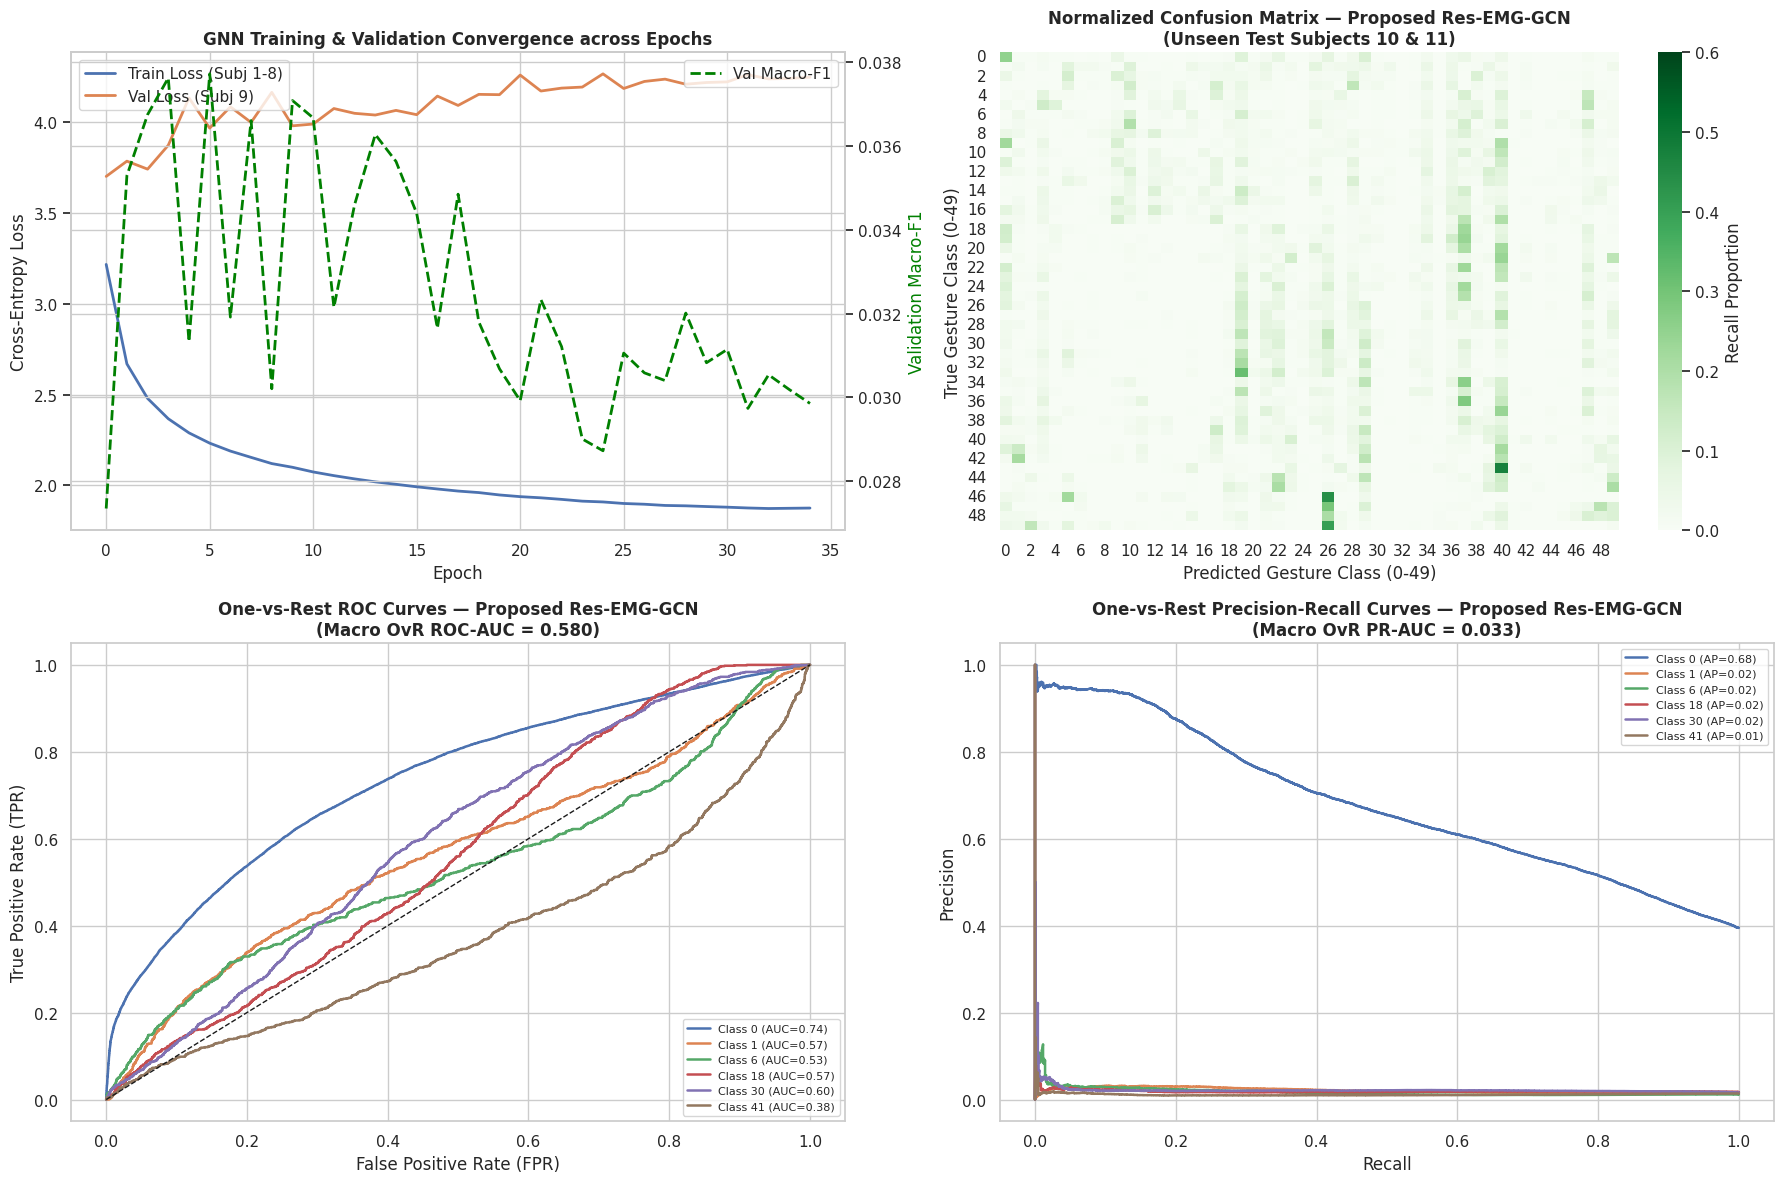

In [ ]:
baseline_csv = '/content/task2_baselines_comparison.csv'
if os.path.exists(baseline_csv):
    df_base = pd.read_csv(baseline_csv)
    df_comp = pd.concat([pd.DataFrame([gnn_metrics]), df_base], ignore_index=True).sort_values(by='Macro-F1', ascending=False).reset_index(drop=True)
else:
    df_comp = pd.DataFrame([gnn_metrics])

display(df_comp)

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

axes[0, 0].plot(history['train_loss'], label='Train Loss (Subj 1-8)', lw=2)
axes[0, 0].plot(history['val_loss'], label='Val Loss (Subj 9)', lw=2)
ax_f1 = axes[0, 0].twinx()
ax_f1.plot(history['val_macro_f1'], color='green', ls='--', lw=2, label='Val Macro-F1')
ax_f1.set_ylabel('Validation Macro-F1', color='green')
axes[0, 0].set_title('GNN Training & Validation Convergence across Epochs', fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Cross-Entropy Loss')
axes[0, 0].legend(loc='upper left'); ax_f1.legend(loc='upper right')

cm_gnn = confusion_matrix(y_test, y_pred_gnn, normalize='true')
sns.heatmap(cm_gnn, cmap='Greens', vmin=0, vmax=0.6, ax=axes[0, 1], cbar_kws={'label': 'Recall Proportion'})
axes[0, 1].set_title('Normalized Confusion Matrix — Proposed Res-EMG-GCN\n(Unseen Test Subjects 10 & 11)', fontweight='bold')
axes[0, 1].set_xlabel('Predicted Gesture Class (0-49)'); axes[0, 1].set_ylabel('True Gesture Class (0-49)')

rep_classes = [0, 1, 6, 18, 30, 41]
for c in rep_classes:
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], y_prob_gnn[:, c])
    axes[1, 0].plot(fpr, tpr, lw=1.8, label=f'Class {c} (AUC={auc(fpr, tpr):.2f})')
axes[1, 0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1, 0].set_title(f'One-vs-Rest ROC Curves — Proposed Res-EMG-GCN\n(Macro OvR ROC-AUC = {gnn_metrics["ROC-AUC (OvR)"]:.3f})', fontweight='bold')
axes[1, 0].set_xlabel('False Positive Rate (FPR)'); axes[1, 0].set_ylabel('True Positive Rate (TPR)')
axes[1, 0].legend(fontsize=8, loc='lower right')

for c in rep_classes:
    prec_c, rec_c, _ = precision_recall_curve(y_test_bin[:, c], y_prob_gnn[:, c])
    axes[1, 1].plot(rec_c, prec_c, lw=1.8, label=f'Class {c} (AP={average_precision_score(y_test_bin[:, c], y_prob_gnn[:, c]):.2f})')
axes[1, 1].set_title(f'One-vs-Rest Precision-Recall Curves — Proposed Res-EMG-GCN\n(Macro OvR PR-AUC = {gnn_metrics["PR-AUC (OvR)"]:.3f})', fontweight='bold')
axes[1, 1].set_xlabel('Recall'); axes[1, 1].set_ylabel('Precision')
axes[1, 1].legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()